In [10]:
from utils.evaluation_utils import run_evaluation_pipeline

# Konfiguration der Modelle
models_to_evaluate = [
    ("deeplab", "deeplab_cityscapes_3258105"),
    ("segformer", "segformer_3266966"),
    ("unet", "unet_3267195"),
    ("deeplab", "deeplab_cityscapes_giga_run_3271161"),
    ("segformer", "segformer_cityscapes_giga_run_3271909"),
    ("unet", "unet_cityscapes_giga_run_3272698"),
]

# Basis-Pfad zu den CVAT-Annotationen
cvat_base_path = "./CVATAnnotations"

Starte Evaluation (Bitte warten, Grafiken werden angezeigt)...
-> Processing: deeplab (deeplab_cityscapes_3258105)
Loaded model: deeplabv3plus
Best checkpoint:
 - Epoch: 199.000
 - Train Loss: 0.070
 - Train Accuracy: 0.960
 - Train MIoU: 0.694
 - Val Loss: 0.154
 - Val Accuracy: 0.929
 - Val MIoU: 0.509


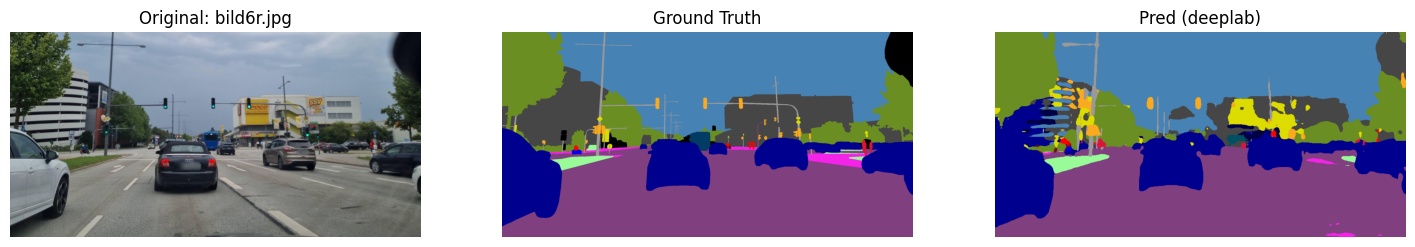

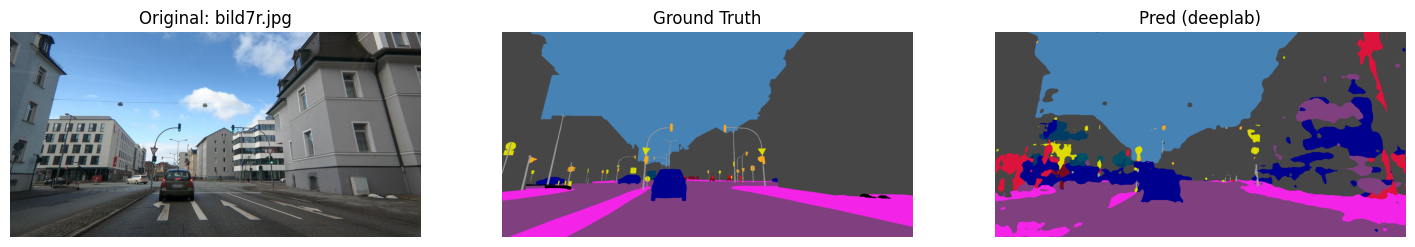

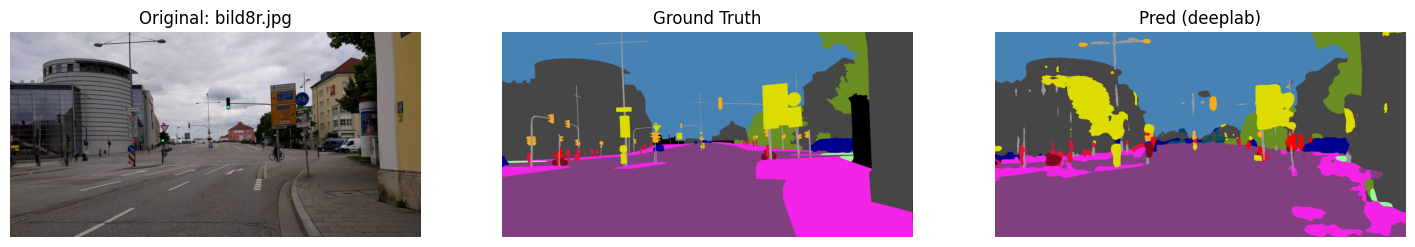

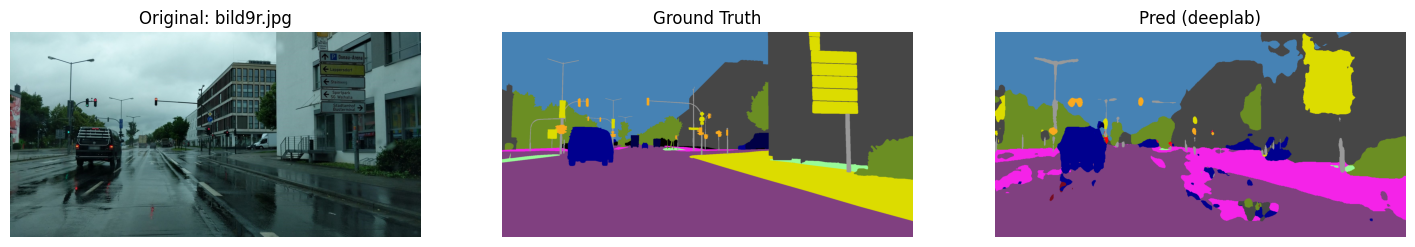

-> Processing: segformer (segformer_3266966)
Loaded model: segformer-b1
Best checkpoint:
 - Epoch: 252.000
 - Train Loss: 0.087
 - Train Accuracy: 0.933
 - Train MIoU: 0.558
 - Val Loss: 0.137
 - Val Accuracy: 0.912
 - Val MIoU: 0.467


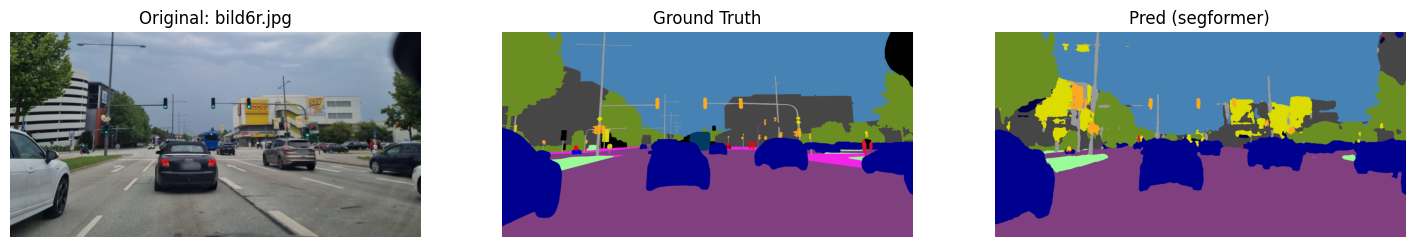

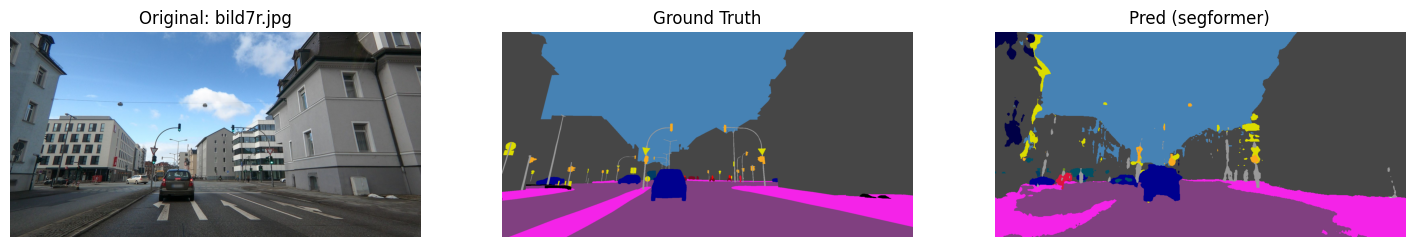

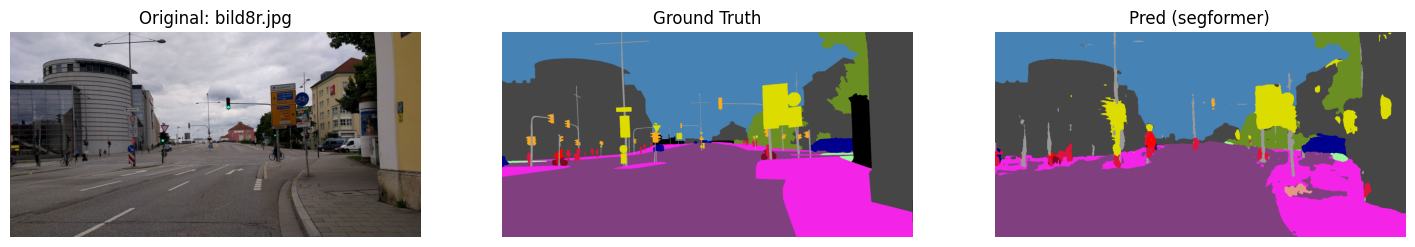

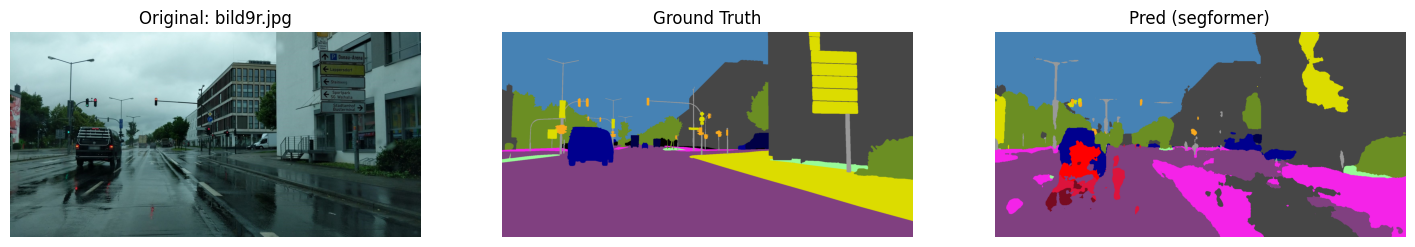

-> Processing: unet (unet_3267195)
Loaded model: u-net
Best checkpoint:
 - Epoch: 234.000
 - Train Loss: 0.206
 - Train Accuracy: 0.882
 - Train MIoU: 0.347
 - Val Loss: 0.235
 - Val Accuracy: 0.874
 - Val MIoU: 0.328


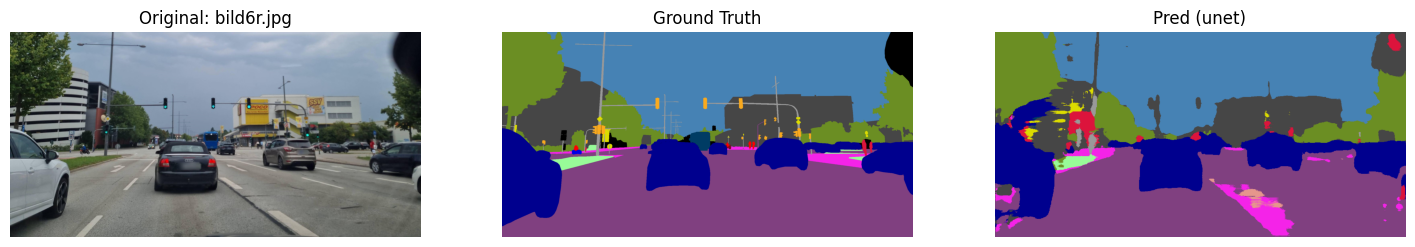

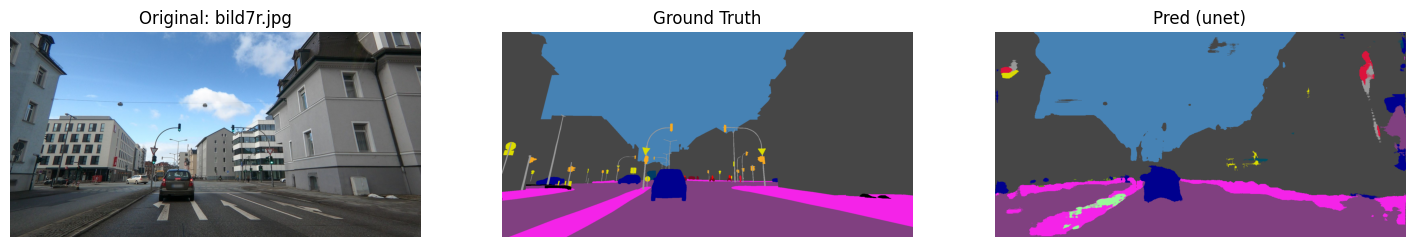

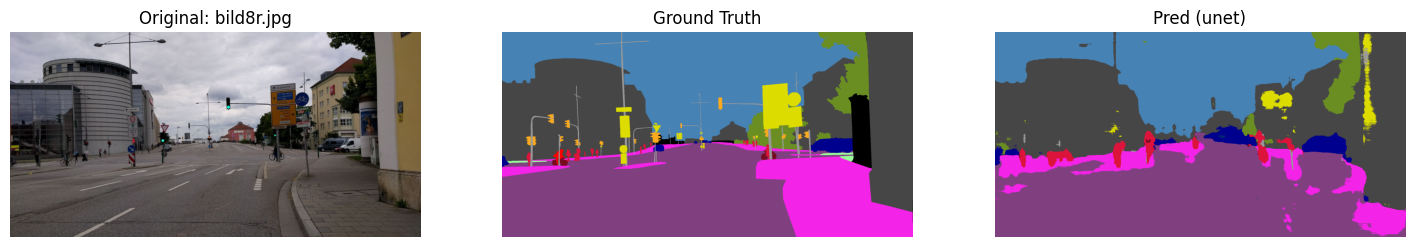

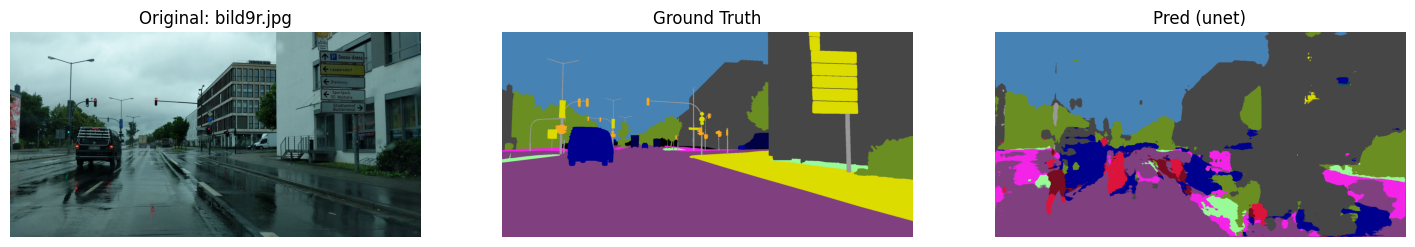

-> Processing: deeplab (deeplab_cityscapes_giga_run_3271161)
Loaded model: deeplabv3plus
Best checkpoint:
 - Epoch: 122.000
 - Train Loss: 0.027
 - Train Accuracy: 0.971
 - Train MIoU: 0.810
 - Val Loss: 0.081
 - Val Accuracy: 0.952
 - Val MIoU: 0.634


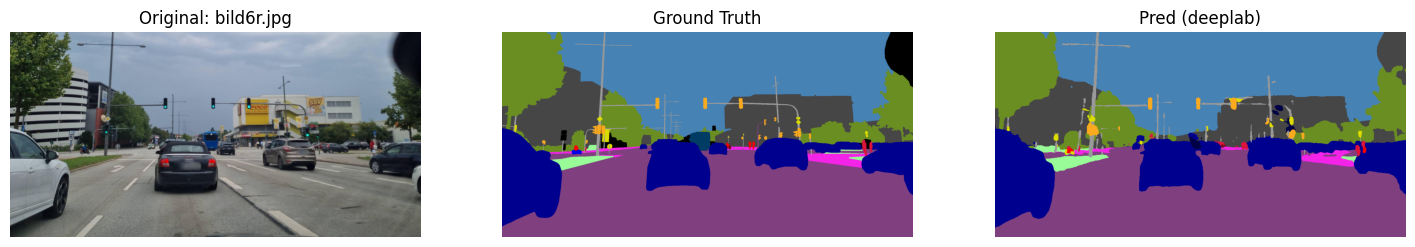

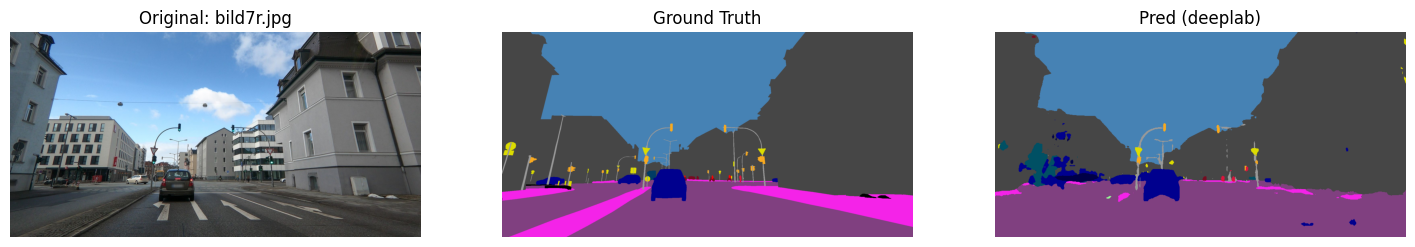

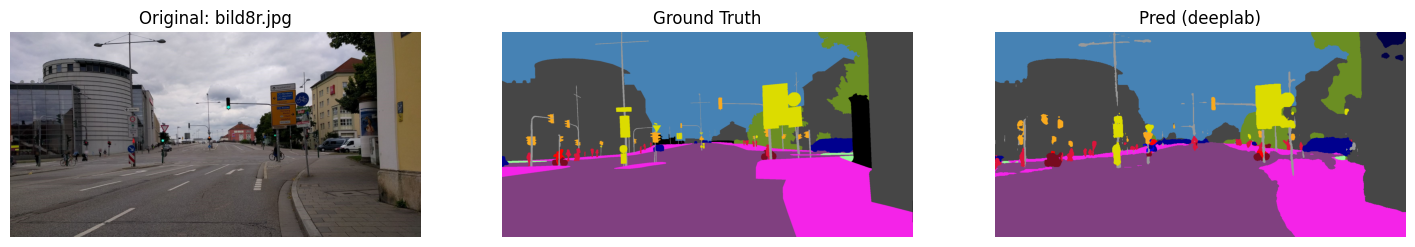

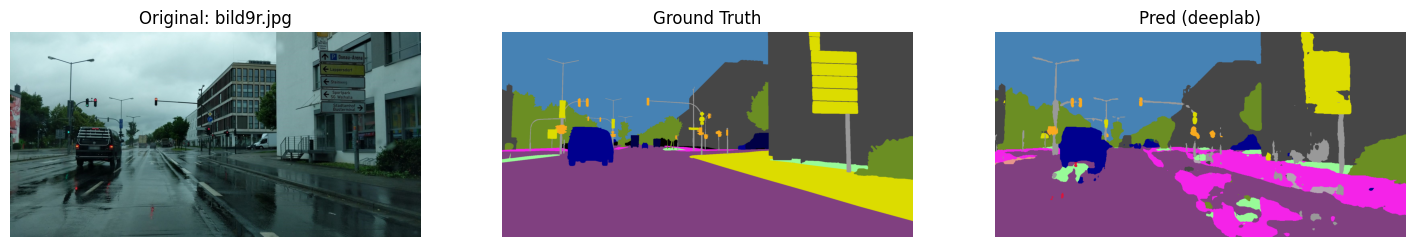

-> Processing: segformer (segformer_cityscapes_giga_run_3271909)
Loaded model: segformer-b1
Best checkpoint:
 - Epoch: 138.000
 - Train Loss: 0.053
 - Train Accuracy: 0.955
 - Train MIoU: 0.688
 - Val Loss: 0.077
 - Val Accuracy: 0.943
 - Val MIoU: 0.599


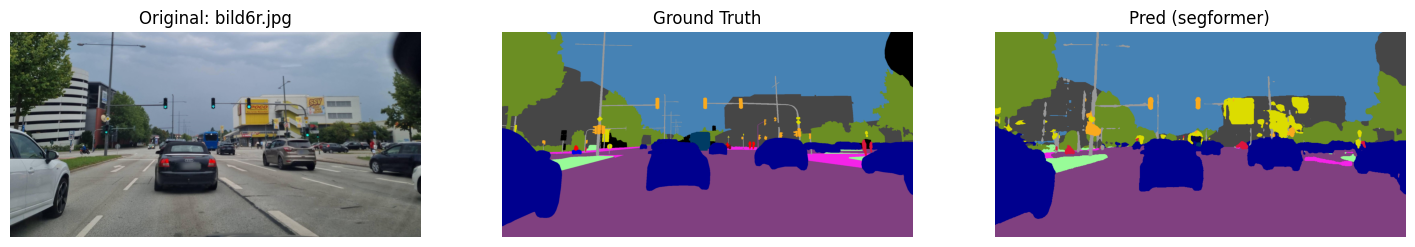

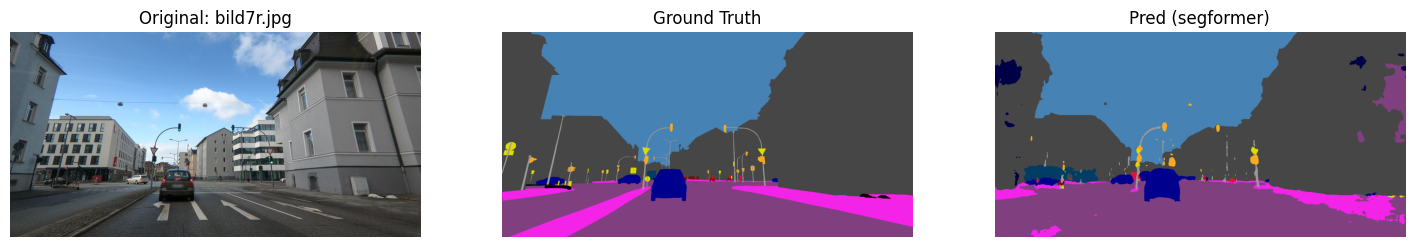

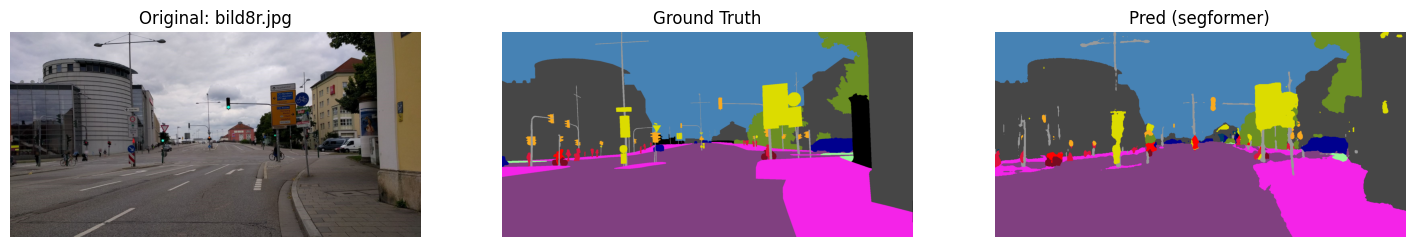

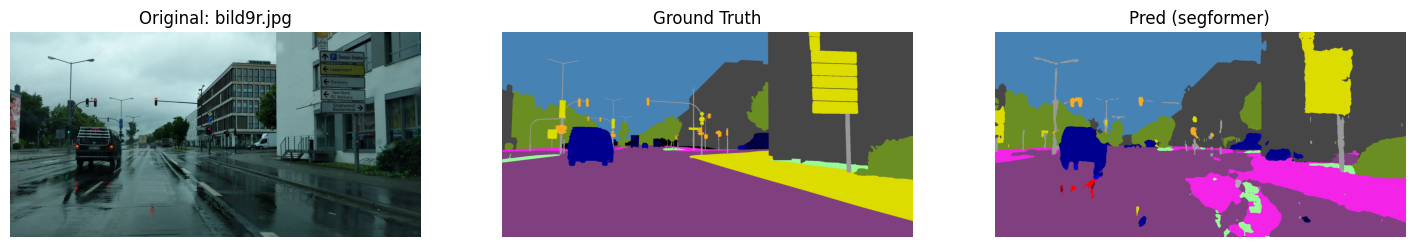

-> Processing: unet (unet_cityscapes_giga_run_3272698)
Loaded model: u-net
Best checkpoint:
 - Epoch: 124.000
 - Train Loss: 0.043
 - Train Accuracy: 0.962
 - Train MIoU: 0.686
 - Val Loss: 0.095
 - Val Accuracy: 0.942
 - Val MIoU: 0.549


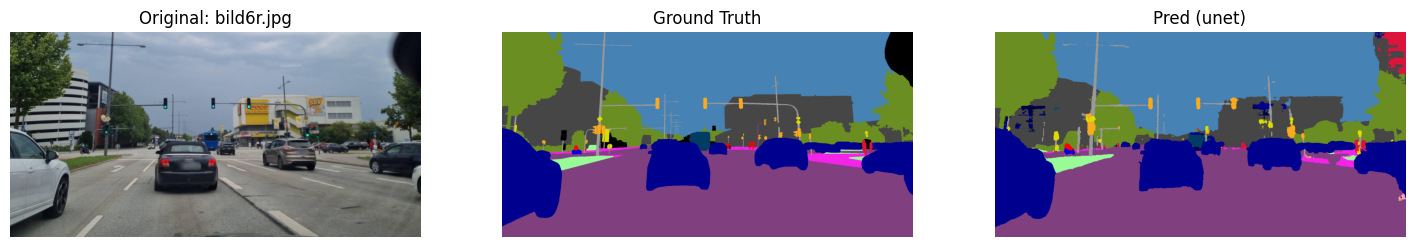

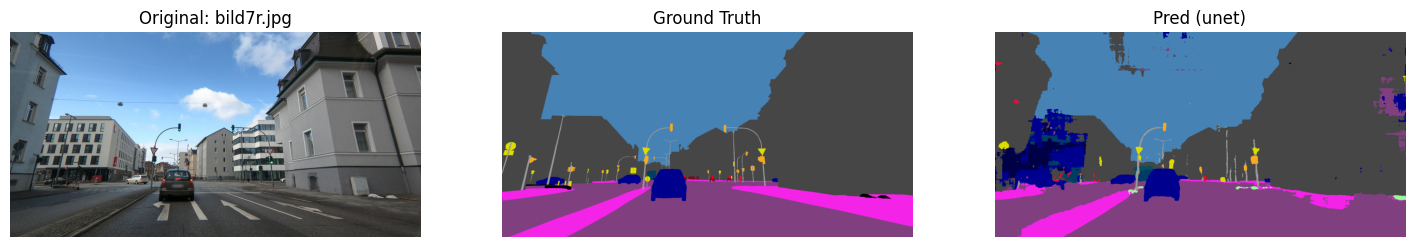

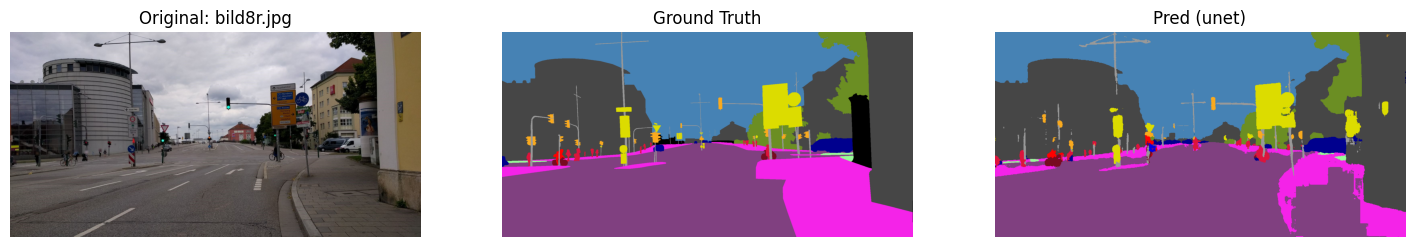

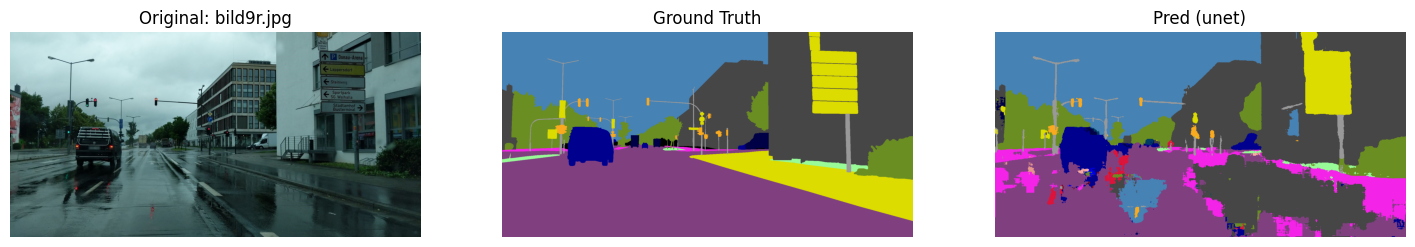

In [12]:
# Liste für die Ergebnisse
all_results = []

print("Starte Evaluation (Bitte warten, Grafiken werden angezeigt)...")

for model_type, checkpoint in models_to_evaluate:
    # Kleiner Hinweis, welches Modell gerade läuft
    print(f"-> Processing: {model_type} ({checkpoint})")

    summary = run_evaluation_pipeline(
        model_type=model_type,
        checkpoint_name=checkpoint,
        base_path=cvat_base_path,
        show_plots=True  # Setze auf False, wenn du GAR KEINE Bilder willst
    )

    if summary:
        all_results.append(summary)

In [14]:
import pandas as pd

# DataFrame erstellen
df_results = pd.DataFrame(all_results)

cols = [
    "Model", "Checkpoint",
    "Train MIoU", "Val (Cityscapes) MIoU", "Eval (Regensburg) MIoU",
    "Train Acc", "Val (Cityscapes) Acc", "Eval (Regensburg) Acc"
]
df_results = df_results[cols]

numeric_cols = df_results.select_dtypes(include=['float64', 'float32']).columns
df_results[numeric_cols] = df_results[numeric_cols].round(3)

# Anzeigen
print("\nFertig! Hier sind die Ergebnisse:")
display(df_results)


Fertig! Hier sind die Ergebnisse:


,Model,Checkpoint,Train MIoU,Val (Cityscapes) MIoU,Eval (Regensburg) MIoU,Train Acc,Val (Cityscapes) Acc,Eval (Regensburg) Acc
0,deeplab,deeplab_cityscapes_3258105,0.694,0.509,0.318,0.960,0.929,0.841
1,segformer,segformer_3266966,0.558,0.467,0.333,0.933,0.912,0.855
2,unet,unet_3267195,0.347,0.328,0.247,0.882,0.874,0.821
3,deeplab,deeplab_cityscapes_giga_run_3271161,0.810,0.634,0.388,0.971,0.952,0.909
4,segformer,segformer_cityscapes_giga_run_3271909,0.688,0.599,0.389,0.955,0.943,0.903
5,unet,unet_cityscapes_giga_run_3272698,0.686,0.549,0.363,0.962,0.942,0.874
